# Zero-Shot vs Few-Shot Performance Comparison

This notebook compares the performance of Llama-3-8B-Instruct with zero-shot and few-shot prompting approaches.

In [1]:
# Setup & Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from sklearn.metrics import confusion_matrix
import warnings
warnings.filterwarnings('ignore')

# Set paths
PROJECT_ROOT = Path("/home/ashrafs/projects/Conspiracy-Proj").resolve()
DATA_DIR = PROJECT_ROOT / "Data"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

# Set plotting style
sns.set_theme(context="notebook", style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (14, 8)
plt.rcParams['font.size'] = 11
%matplotlib inline

print("✓ Setup complete!")

✓ Setup complete!


In [ ]:
# Load Data
human_class = pd.read_csv(DATA_DIR / "all_classifications.csv")
human_class_unique = human_class.drop_duplicates(subset="text_id", keep="first")

zeroshot = pd.read_csv(OUTPUT_DIR / "llama8b-zeroshot_all_classifications.csv")
fewshot = pd.read_csv(OUTPUT_DIR / "llama8b-fewshot_all_classifications.csv")

print(f"Human annotations: {len(human_class_unique)} texts")
print(f"Zero-Shot annotations: {len(zeroshot)} texts")
print(f"Few-Shot annotations: {len(fewshot)} texts")


Human annotations: 2077 texts
Zero-Shot annotations: 2077 texts
Few-Shot annotations: 2077 texts


In [ ]:
# Helper function to calculate metrics
def calculate_metrics(human_df, llm_df, label='conspiracy'):
    """Calculate classification metrics"""
    def yn_to_bool(val):
        if pd.isna(val):
            return False
        val_str = str(val).lower().strip()
        return val_str == 'yes' or val_str == 'true'
    
    merged = human_df.merge(
        llm_df[['text_id', label]],
        on='text_id',
        suffixes=('_human', '_llm'),
        how='inner'
    )
    
    human_col = f'{label}_human'
    llm_col = f'{label}_llm'
    
    merged['human_bool'] = merged[human_col].apply(yn_to_bool).astype(bool)
    merged['llm_bool'] = merged[llm_col].apply(yn_to_bool).astype(bool)
    
    mask = merged['human_bool'].notna() & merged['llm_bool'].notna()
    data = merged[mask].copy()
    
    if len(data) == 0:
        return None, None
    
    data['human_bool'] = data['human_bool'].astype(bool)
    data['llm_bool'] = data['llm_bool'].astype(bool)
    
    cm = confusion_matrix(data['human_bool'], data['llm_bool'], labels=[True, False])
    tp, fn = cm[0,0], cm[0,1]
    fp, tn = cm[1,0], cm[1,1]
    
    accuracy = (tp + tn) / (tp + tn + fp + fn) if (tp + tn + fp + fn) > 0 else 0
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    agreement = (merged['human_bool'] == merged['llm_bool']).mean()
    
    metrics = {
        'accuracy': accuracy,
        'precision': precision,
        'recall': recall,
        'f1': f1,
        'agreement': agreement,
        'tp': int(tp), 'tn': int(tn), 'fp': int(fp), 'fn': int(fn),
        'total': len(merged)
    }
    
    return metrics, cm

# Calculate metrics for both approaches
zs_metrics, zs_cm = calculate_metrics(human_class_unique, zeroshot, 'conspiracy')
fs_metrics, fs_cm = calculate_metrics(human_class_unique, fewshot, 'conspiracy')

print("✓ Metrics calculated!")


✓ Metrics calculated!


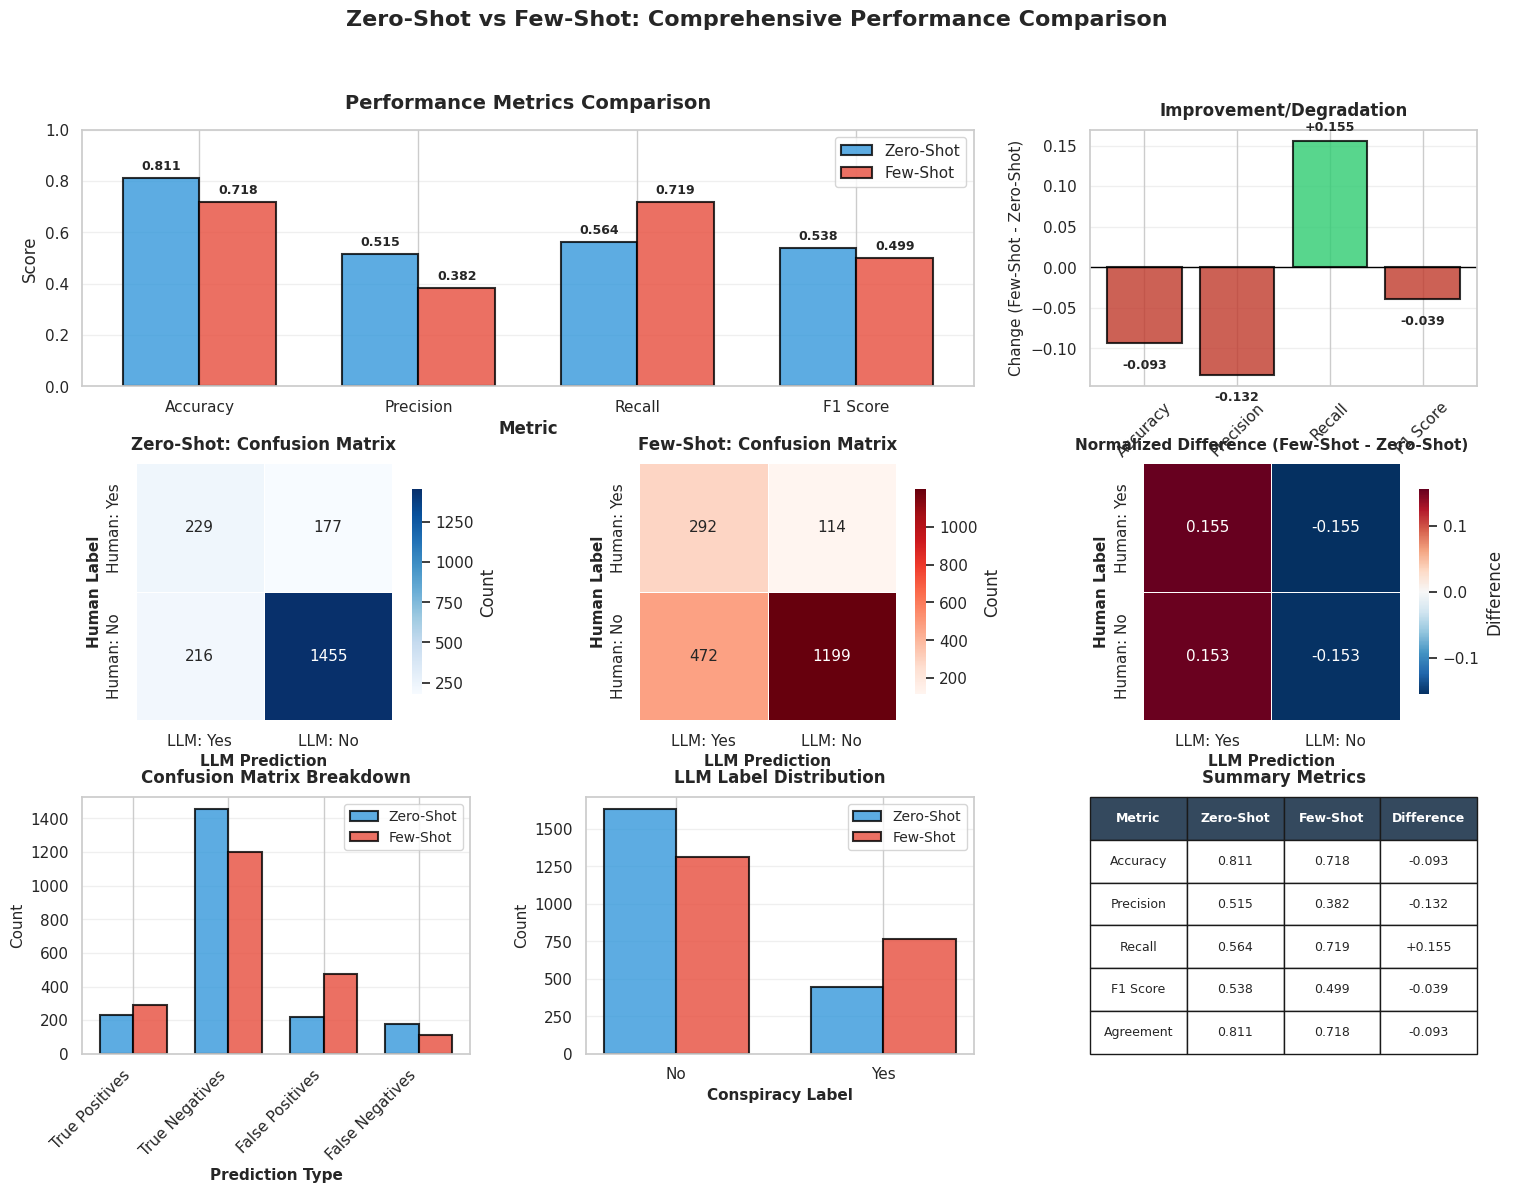

✓ Comparison visualization saved to plots/zeroshot_vs_fewshot_comparison.png


In [ ]:
# Comprehensive Comparison Visualization
fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# 1. Metrics Comparison Bar Chart
ax1 = fig.add_subplot(gs[0, :2])
metrics_names = ['Accuracy', 'Precision', 'Recall', 'F1 Score']
zs_values = [zs_metrics['accuracy'], zs_metrics['precision'], 
             zs_metrics['recall'], zs_metrics['f1']]
fs_values = [fs_metrics['accuracy'], fs_metrics['precision'], 
             fs_metrics['recall'], fs_metrics['f1']]

x = np.arange(len(metrics_names))
width = 0.35

bars1 = ax1.bar(x - width/2, zs_values, width, label='Zero-Shot', 
                color='#3498db', alpha=0.8, edgecolor='black', linewidth=1.5)
bars2 = ax1.bar(x + width/2, fs_values, width, label='Few-Shot', 
                color='#e74c3c', alpha=0.8, edgecolor='black', linewidth=1.5)

ax1.set_xlabel('Metric', fontsize=12, fontweight='bold')
ax1.set_ylabel('Score', fontsize=12)
ax1.set_title('Performance Metrics Comparison', fontsize=14, fontweight='bold', pad=15)
ax1.set_xticks(x)
ax1.set_xticklabels(metrics_names)
ax1.legend(fontsize=11)
ax1.grid(axis='y', alpha=0.3)
ax1.set_ylim(0, 1.0)

# Add value labels
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax1.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{height:.3f}', ha='center', va='bottom', fontsize=9, fontweight='bold')

# 2. Improvement/Degradation Bar Chart
ax2 = fig.add_subplot(gs[0, 2])
improvements = [fs - zs for zs, fs in zip(zs_values, fs_values)]
colors_imp = ['#2ecc71' if imp > 0 else '#c0392b' for imp in improvements]
bars3 = ax2.bar(metrics_names, improvements, color=colors_imp, alpha=0.8, 
                edgecolor='black', linewidth=1.5)
ax2.axhline(y=0, color='black', linestyle='-', linewidth=1)
ax2.set_ylabel('Change (Few-Shot - Zero-Shot)', fontsize=11)
ax2.set_title('Improvement/Degradation', fontsize=12, fontweight='bold', pad=10)
ax2.tick_params(axis='x', rotation=45)
ax2.grid(axis='y', alpha=0.3)

for bar, imp in zip(bars3, improvements):
    height = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2., 
            height + (0.01 if height > 0 else -0.02),
            f'{imp:+.3f}', ha='center', va='bottom' if height > 0 else 'top', 
            fontsize=9, fontweight='bold')

# 3. Confusion Matrix - Zero-Shot
ax3 = fig.add_subplot(gs[1, 0])
sns.heatmap(zs_cm, annot=True, fmt='d', cmap='Blues', ax=ax3,
            xticklabels=['LLM: Yes', 'LLM: No'], 
            yticklabels=['Human: Yes', 'Human: No'],
            cbar_kws={'label': 'Count', 'shrink': 0.8}, 
            square=True, linewidths=0.5)
ax3.set_xlabel('LLM Prediction', fontsize=11, fontweight='bold')
ax3.set_ylabel('Human Label', fontsize=11, fontweight='bold')
ax3.set_title('Zero-Shot: Confusion Matrix', fontsize=12, fontweight='bold', pad=10)

# 4. Confusion Matrix - Few-Shot
ax4 = fig.add_subplot(gs[1, 1])
sns.heatmap(fs_cm, annot=True, fmt='d', cmap='Reds', ax=ax4,
            xticklabels=['LLM: Yes', 'LLM: No'], 
            yticklabels=['Human: Yes', 'Human: No'],
            cbar_kws={'label': 'Count', 'shrink': 0.8}, 
            square=True, linewidths=0.5)
ax4.set_xlabel('LLM Prediction', fontsize=11, fontweight='bold')
ax4.set_ylabel('Human Label', fontsize=11, fontweight='bold')
ax4.set_title('Few-Shot: Confusion Matrix', fontsize=12, fontweight='bold', pad=10)

# 5. Normalized Difference
ax5 = fig.add_subplot(gs[1, 2])
zs_cm_norm = zs_cm.astype('float') / zs_cm.sum(axis=1)[:, np.newaxis]
fs_cm_norm = fs_cm.astype('float') / fs_cm.sum(axis=1)[:, np.newaxis]
cm_diff = fs_cm_norm - zs_cm_norm
sns.heatmap(cm_diff, annot=True, fmt='.3f', cmap='RdBu_r', center=0, ax=ax5,
            xticklabels=['LLM: Yes', 'LLM: No'], 
            yticklabels=['Human: Yes', 'Human: No'],
            cbar_kws={'label': 'Difference', 'shrink': 0.8}, 
            square=True, linewidths=0.5)
ax5.set_xlabel('LLM Prediction', fontsize=11, fontweight='bold')
ax5.set_ylabel('Human Label', fontsize=11, fontweight='bold')
ax5.set_title('Normalized Difference (Few-Shot - Zero-Shot)', fontsize=11, fontweight='bold', pad=10)

# 6. Error Analysis
ax6 = fig.add_subplot(gs[2, 0])
error_types = ['True Positives', 'True Negatives', 'False Positives', 'False Negatives']
zs_counts = [zs_metrics['tp'], zs_metrics['tn'], zs_metrics['fp'], zs_metrics['fn']]
fs_counts = [fs_metrics['tp'], fs_metrics['tn'], fs_metrics['fp'], fs_metrics['fn']]

x_err = np.arange(len(error_types))
bars4 = ax6.bar(x_err - width/2, zs_counts, width, label='Zero-Shot', 
               color='#3498db', alpha=0.8, edgecolor='black', linewidth=1.5)
bars5 = ax6.bar(x_err + width/2, fs_counts, width, label='Few-Shot', 
               color='#e74c3c', alpha=0.8, edgecolor='black', linewidth=1.5)

ax6.set_xlabel('Prediction Type', fontsize=11, fontweight='bold')
ax6.set_ylabel('Count', fontsize=11)
ax6.set_title('Confusion Matrix Breakdown', fontsize=12, fontweight='bold', pad=10)
ax6.set_xticks(x_err)
ax6.set_xticklabels(error_types, rotation=45, ha='right')
ax6.legend(fontsize=10)
ax6.grid(axis='y', alpha=0.3)

# 7. Label Distribution Comparison
ax7 = fig.add_subplot(gs[2, 1])
zs_dist = zeroshot['conspiracy'].value_counts().sort_index()
fs_dist = fewshot['conspiracy'].value_counts().sort_index()

labels_dist = ['No', 'Yes']
x_dist = np.arange(len(labels_dist))
bars6 = ax7.bar(x_dist - width/2, [zs_dist.get('no', 0), zs_dist.get('yes', 0)], 
               width, label='Zero-Shot', color='#3498db', alpha=0.8, 
               edgecolor='black', linewidth=1.5)
bars7 = ax7.bar(x_dist + width/2, [fs_dist.get('no', 0), fs_dist.get('yes', 0)], 
               width, label='Few-Shot', color='#e74c3c', alpha=0.8, 
               edgecolor='black', linewidth=1.5)

ax7.set_xlabel('Conspiracy Label', fontsize=11, fontweight='bold')
ax7.set_ylabel('Count', fontsize=11)
ax7.set_title('LLM Label Distribution', fontsize=12, fontweight='bold', pad=10)
ax7.set_xticks(x_dist)
ax7.set_xticklabels(labels_dist)
ax7.legend(fontsize=10)
ax7.grid(axis='y', alpha=0.3)

# 8. Summary Table
ax8 = fig.add_subplot(gs[2, 2])
ax8.axis('off')
summary_data = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1 Score', 'Agreement'],
    'Zero-Shot': [f"{zs_metrics['accuracy']:.3f}", f"{zs_metrics['precision']:.3f}",
                  f"{zs_metrics['recall']:.3f}", f"{zs_metrics['f1']:.3f}",
                  f"{zs_metrics['agreement']:.3f}"],
    'Few-Shot': [f"{fs_metrics['accuracy']:.3f}", f"{fs_metrics['precision']:.3f}",
                 f"{fs_metrics['recall']:.3f}", f"{fs_metrics['f1']:.3f}",
                 f"{fs_metrics['agreement']:.3f}"],
    'Difference': [f"{fs_metrics['accuracy']-zs_metrics['accuracy']:+.3f}",
                   f"{fs_metrics['precision']-zs_metrics['precision']:+.3f}",
                   f"{fs_metrics['recall']-zs_metrics['recall']:+.3f}",
                   f"{fs_metrics['f1']-zs_metrics['f1']:+.3f}",
                   f"{fs_metrics['agreement']-zs_metrics['agreement']:+.3f}"]
}
summary_df = pd.DataFrame(summary_data)
table = ax8.table(cellText=summary_df.values, colLabels=summary_df.columns,
                  cellLoc='center', loc='center', bbox=[0, 0, 1, 1])
table.auto_set_font_size(False)
table.set_fontsize(9)
table.scale(1, 2)
for i in range(len(summary_df.columns)):
    table[(0, i)].set_facecolor('#34495e')
    table[(0, i)].set_text_props(weight='bold', color='white')
ax8.set_title('Summary Metrics', fontsize=12, fontweight='bold', pad=10)

plt.suptitle('Zero-Shot vs Few-Shot: Comprehensive Performance Comparison', 
             fontsize=16, fontweight='bold', y=0.98)
plt.savefig(PROJECT_ROOT / 'plots' / 'zeroshot_vs_fewshot_comparison.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Comparison visualization saved to plots/zeroshot_vs_fewshot_comparison.png")


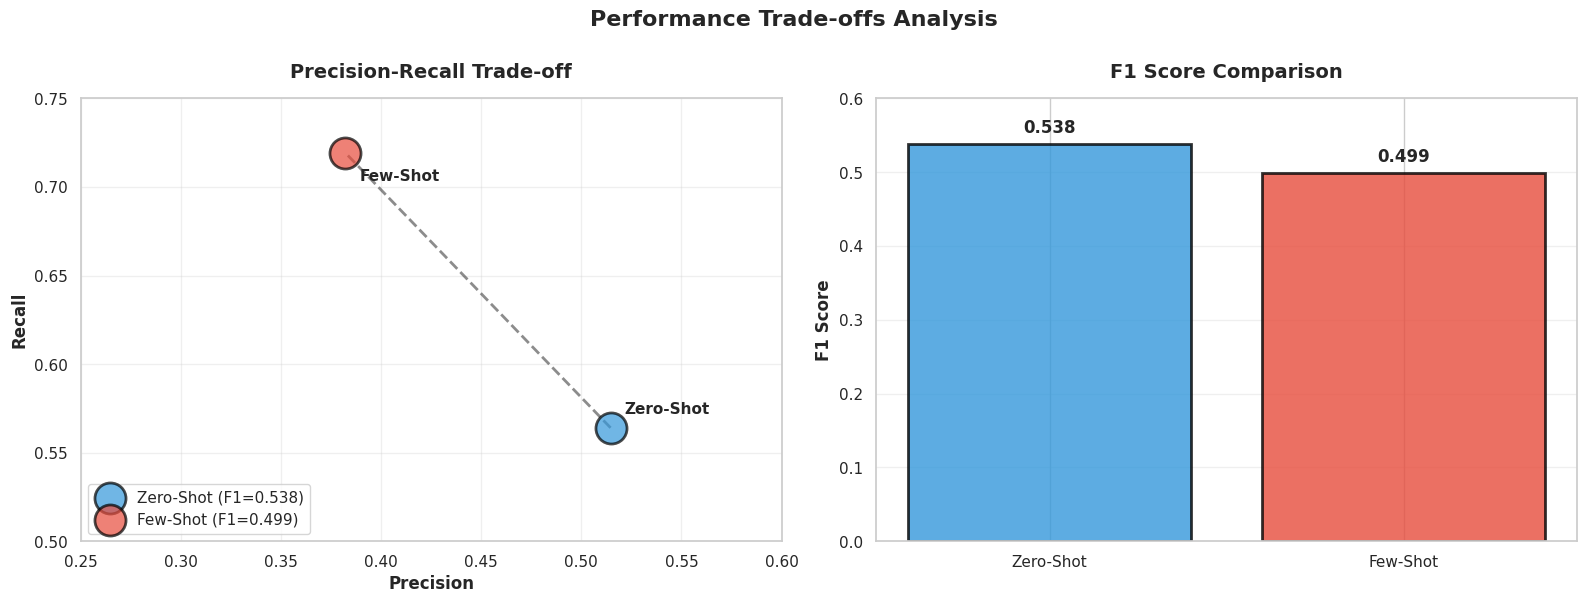

✓ Trade-off analysis saved to plots/zeroshot_vs_fewshot_tradeoffs.png


In [ ]:
# Precision-Recall Trade-off Visualization
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# Precision-Recall Plot
ax1.scatter(zs_metrics['precision'], zs_metrics['recall'], 
           s=500, color='#3498db', alpha=0.7, edgecolors='black', linewidth=2,
           label=f'Zero-Shot (F1={zs_metrics["f1"]:.3f})', zorder=3)
ax1.scatter(fs_metrics['precision'], fs_metrics['recall'], 
           s=500, color='#e74c3c', alpha=0.7, edgecolors='black', linewidth=2,
           label=f'Few-Shot (F1={fs_metrics["f1"]:.3f})', zorder=3)

ax1.plot([zs_metrics['precision'], fs_metrics['precision']], 
         [zs_metrics['recall'], fs_metrics['recall']], 
         'k--', alpha=0.5, linewidth=2, zorder=1)

ax1.annotate('Zero-Shot', (zs_metrics['precision'], zs_metrics['recall']),
            xytext=(10, 10), textcoords='offset points', fontsize=11, fontweight='bold')
ax1.annotate('Few-Shot', (fs_metrics['precision'], fs_metrics['recall']),
            xytext=(10, -20), textcoords='offset points', fontsize=11, fontweight='bold')

ax1.set_xlabel('Precision', fontsize=12, fontweight='bold')
ax1.set_ylabel('Recall', fontsize=12, fontweight='bold')
ax1.set_title('Precision-Recall Trade-off', fontsize=14, fontweight='bold', pad=15)
ax1.grid(True, alpha=0.3)
ax1.set_xlim(0.25, 0.6)
ax1.set_ylim(0.5, 0.75)
ax1.legend(fontsize=11, loc='lower left')

# F1 Score Comparison
ax2.bar(['Zero-Shot', 'Few-Shot'], 
       [zs_metrics['f1'], fs_metrics['f1']],
       color=['#3498db', '#e74c3c'], alpha=0.8, edgecolor='black', linewidth=2)
ax2.set_ylabel('F1 Score', fontsize=12, fontweight='bold')
ax2.set_title('F1 Score Comparison', fontsize=14, fontweight='bold', pad=15)
ax2.set_ylim(0, 0.6)
ax2.grid(axis='y', alpha=0.3)

# Add value labels
for i, (label, val) in enumerate(zip(['Zero-Shot', 'Few-Shot'], 
                                     [zs_metrics['f1'], fs_metrics['f1']])):
    ax2.text(i, val + 0.01, f'{val:.3f}', ha='center', va='bottom', 
            fontsize=12, fontweight='bold')

plt.suptitle('Performance Trade-offs Analysis', fontsize=16, fontweight='bold', y=1.0)
plt.tight_layout()
plt.savefig(PROJECT_ROOT / 'plots' / 'zeroshot_vs_fewshot_tradeoffs.png', 
            dpi=300, bbox_inches='tight')
plt.show()

print("✓ Trade-off analysis saved to plots/zeroshot_vs_fewshot_tradeoffs.png")


In [ ]:
# Print detailed comparison
print("=" * 70)
print("DETAILED PERFORMANCE COMPARISON")
print("=" * 70)
print(f"\nDataset Size: {zs_metrics['total']} texts\n")

print("CONSPIRACY LABEL METRICS:")
print("-" * 70)
print(f"{'Metric':<15} {'Zero-Shot':<15} {'Few-Shot':<15} {'Difference':<15}")
print("-" * 70)
print(f"{'Accuracy':<15} {zs_metrics['accuracy']:<15.3f} {fs_metrics['accuracy']:<15.3f} {fs_metrics['accuracy']-zs_metrics['accuracy']:+.3f}")
print(f"{'Precision':<15} {zs_metrics['precision']:<15.3f} {fs_metrics['precision']:<15.3f} {fs_metrics['precision']-zs_metrics['precision']:+.3f}")
print(f"{'Recall':<15} {zs_metrics['recall']:<15.3f} {fs_metrics['recall']:<15.3f} {fs_metrics['recall']-zs_metrics['recall']:+.3f}")
print(f"{'F1 Score':<15} {zs_metrics['f1']:<15.3f} {fs_metrics['f1']:<15.3f} {fs_metrics['f1']-zs_metrics['f1']:+.3f}")
print(f"{'Agreement':<15} {zs_metrics['agreement']:<15.3f} {fs_metrics['agreement']:<15.3f} {fs_metrics['agreement']-zs_metrics['agreement']:+.3f}")

print("\nCONFUSION MATRIX:")
print("-" * 70)
print(f"{'Metric':<20} {'Zero-Shot':<15} {'Few-Shot':<15} {'Difference':<15}")
print("-" * 70)
print(f"{'True Positives':<20} {zs_metrics['tp']:<15} {fs_metrics['tp']:<15} {fs_metrics['tp']-zs_metrics['tp']:+d}")
print(f"{'True Negatives':<20} {zs_metrics['tn']:<15} {fs_metrics['tn']:<15} {fs_metrics['tn']-zs_metrics['tn']:+d}")
print(f"{'False Positives':<20} {zs_metrics['fp']:<15} {fs_metrics['fp']:<15} {fs_metrics['fp']-zs_metrics['fp']:+d}")
print(f"{'False Negatives':<20} {zs_metrics['fn']:<15} {fs_metrics['fn']:<15} {fs_metrics['fn']-zs_metrics['fn']:+d}")

print("\nLABEL DISTRIBUTION:")
print("-" * 70)
zs_dist = zeroshot['conspiracy'].value_counts().sort_index()
fs_dist = fewshot['conspiracy'].value_counts().sort_index()
print(f"Zero-Shot: {zs_dist.get('no', 0)} No, {zs_dist.get('yes', 0)} Yes")
print(f"Few-Shot:  {fs_dist.get('no', 0)} No, {fs_dist.get('yes', 0)} Yes")
print(f"Difference: {(fs_dist.get('yes', 0) - zs_dist.get('yes', 0)):+d} more 'Yes' predictions in Few-Shot")

print("\nKEY INSIGHTS:")
print("-" * 70)
if fs_metrics['recall'] > zs_metrics['recall']:
    print(f"✓ Few-Shot has HIGHER recall (+{(fs_metrics['recall']-zs_metrics['recall'])*100:.1f}%), "
          f"catching {(fs_metrics['tp']-zs_metrics['tp'])} more true positives")
if zs_metrics['precision'] > fs_metrics['precision']:
    print(f"✓ Zero-Shot has HIGHER precision (+{(zs_metrics['precision']-fs_metrics['precision'])*100:.1f}%), "
          f"with {(zs_metrics['fp']-fs_metrics['fp'])} fewer false positives")
if zs_metrics['accuracy'] > fs_metrics['accuracy']:
    print(f"✓ Zero-Shot has HIGHER overall accuracy (+{(zs_metrics['accuracy']-fs_metrics['accuracy'])*100:.1f}%)")
else:
    print(f"✓ Few-Shot has HIGHER overall accuracy (+{(fs_metrics['accuracy']-zs_metrics['accuracy'])*100:.1f}%)")


DETAILED PERFORMANCE COMPARISON

Dataset Size: 2077 texts

CONSPIRACY LABEL METRICS:
----------------------------------------------------------------------
Metric          Zero-Shot       Few-Shot        Difference     
----------------------------------------------------------------------
Accuracy        0.811           0.718           -0.093
Precision       0.515           0.382           -0.132
Recall          0.564           0.719           +0.155
F1 Score        0.538           0.499           -0.039
Agreement       0.811           0.718           -0.093

CONFUSION MATRIX:
----------------------------------------------------------------------
Metric               Zero-Shot       Few-Shot        Difference     
----------------------------------------------------------------------
True Positives       229             292             +63
True Negatives       1455            1199            -256
False Positives      216             472             +256
False Negatives      177       